In [ ]:

!pip install -q diffusers transformers accelerate
!pip install -q controlnet-aux opencv-python
!pip install -q gradio scikit-image pandas matplotlib
!pip install -q sentencepiece

In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU in Colab Runtime settings.")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from pathlib import Path

print("All basic libraries imported successfully!")

All basic libraries imported successfully!


In [ ]:

data = [
    {
        "product": "Ball Bearing",
        "material": "Chrome Steel",
        "bore_mm": 20,
        "outer_diameter_mm": 47,
        "width_mm": 14,
        "features": "Inner ring, outer ring, sealed design"
    },
    {
        "product": "Hex Bolt",
        "material": "Stainless Steel",
        "bore_mm": 0,
        "outer_diameter_mm": 10,
        "width_mm": 50,
        "features": "Hexagonal head, threaded shaft"
    },
    {
        "product": "Metal Gear",
        "material": "Alloy Steel",
        "bore_mm": 15,
        "outer_diameter_mm": 60,
        "width_mm": 12,
        "features": "Central hole, external teeth"
    }
]

df = pd.DataFrame(data)

print(df)

        product         material  bore_mm  outer_diameter_mm  width_mm  \
0  Ball Bearing     Chrome Steel       20                 47        14   
1      Hex Bolt  Stainless Steel        0                 10        50   
2    Metal Gear      Alloy Steel       15                 60        12   

                                features  
0  Inner ring, outer ring, sealed design  
1         Hexagonal head, threaded shaft  
2           Central hole, external teeth  


In [ ]:

import pandas as pd

products = [
    ("Ball Bearing", "Chrome Steel", 20, 47, 14, "Inner ring, outer ring, sealed"),
    ("Deep Groove Bearing", "Chrome Steel", 25, 52, 15, "Inner ring, outer ring, balls"),
    ("Hex Bolt", "Stainless Steel", 0, 10, 50, "Hex head, threaded shaft"),
    ("Hex Nut", "Stainless Steel", 10, 17, 8, "Hexagonal body, central hole"),
    ("Steel Gear", "Alloy Steel", 15, 60, 12, "Central hole, external teeth"),
    ("Flat Washer", "Stainless Steel", 10, 25, 2, "Central hole, flat circular body"),
    ("Spring Washer", "Steel", 10, 20, 3, "Split ring, spring structure"),
    ("Flange", "Carbon Steel", 20, 80, 10, "Circular plate, bolt holes"),
    ("Pipe Coupling", "Stainless Steel", 20, 35, 40, "Cylindrical body, threaded ends"),
    ("Pulley", "Cast Iron", 15, 100, 25, "Grooved wheel, central bore"),
    ("Shaft", "Alloy Steel", 20, 40, 150, "Cylindrical shaft, stepped ends"),
    ("Spacer", "Aluminium", 10, 20, 15, "Cylindrical hollow body"),
    ("Retaining Ring", "Spring Steel", 15, 30, 2, "Split circular ring"),
    ("O Ring", "Rubber", 10, 20, 3, "Circular sealing ring"),
    ("Metal Bracket", "Mild Steel", 0, 50, 40, "L-shaped body, mounting holes"),
    ("Steel Pin", "Stainless Steel", 5, 10, 30, "Solid cylindrical pin"),
    ("Dowel Pin", "Hardened Steel", 6, 12, 25, "Smooth cylindrical body"),
    ("Sprocket", "Alloy Steel", 15, 80, 10, "Central bore, chain teeth"),
    ("V Belt Pulley", "Cast Iron", 20, 120, 30, "V-shaped grooves, central bore"),
    ("Bearing Housing", "Cast Iron", 25, 100, 50, "Housing body, mounting holes"),
    ("Metal Clamp", "Stainless Steel", 0, 40, 20, "Clamping arms, screw"),
    ("Pipe Elbow", "Stainless Steel", 25, 40, 50, "90 degree curved pipe"),
    ("Tee Joint", "PVC", 25, 50, 50, "Three connected openings"),
    ("Metal Cap", "Aluminium", 0, 30, 20, "Cylindrical closed end"),
    ("Threaded Rod", "Stainless Steel", 0, 12, 100, "External threads"),
    ("Lead Screw", "Alloy Steel", 10, 25, 100, "Helical thread, cylindrical shaft"),
    ("Metal Hinge", "Stainless Steel", 0, 30, 50, "Two leaves, central pin"),
    ("Door Handle", "Aluminium", 0, 30, 120, "Curved grip, mounting base"),
    ("Gear Shaft", "Alloy Steel", 15, 45, 120, "Gear teeth, stepped shaft"),
    ("Metal Disc", "Aluminium", 10, 80, 8, "Flat circular plate, central hole"),
    ("Flange Bearing", "Chrome Steel", 20, 65, 25, "Flange, bearing rings"),
    ("Hex Socket Screw", "Stainless Steel", 0, 8, 35, "Socket head, threaded shaft"),
    ("Lock Washer", "Spring Steel", 8, 18, 2, "Split ring, locking edges"),
    ("Metal Sleeve", "Brass", 12, 25, 40, "Hollow cylindrical body"),
    ("Cylinder Piston", "Aluminium", 0, 50, 60, "Circular piston head, rod"),
    ("Nozzle", "Brass", 5, 20, 35, "Tapered body, narrow opening"),
    ("Metal Valve", "Stainless Steel", 15, 50, 70, "Valve body, inlet and outlet"),
    ("Pipe Reducer", "Stainless Steel", 30, 50, 40, "Conical transition, two openings"),
    ("Metal Coupler", "Steel", 15, 35, 45, "Cylindrical connector"),
    ("Industrial Gearbox", "Cast Iron", 20, 150, 100, "Housing, shafts, mounting points")
]

df = pd.DataFrame(products, columns=[
    "product", "material", "bore_mm",
    "outer_diameter_mm", "width_mm", "features"
])

df.to_csv("industrial_dataset.csv", index=False)

print("Dataset created successfully!")
print("Total products:", len(df))
display(df.head(10))

Dataset created successfully!
Total products: 40


,product,material,bore_mm,outer_diameter_mm,width_mm,features
0,Ball Bearing,Chrome Steel,20,47,14,"Inner ring, outer ring, sealed"
1,Deep Groove Bearing,Chrome Steel,25,52,15,"Inner ring, outer ring, balls"
2,Hex Bolt,Stainless Steel,0,10,50,"Hex head, threaded shaft"
3,Hex Nut,Stainless Steel,10,17,8,"Hexagonal body, central hole"
4,Steel Gear,Alloy Steel,15,60,12,"Central hole, external teeth"
5,Flat Washer,Stainless Steel,10,25,2,"Central hole, flat circular body"
6,Spring Washer,Steel,10,20,3,"Split ring, spring structure"
7,Flange,Carbon Steel,20,80,10,"Circular plate, bolt holes"
8,Pipe Coupling,Stainless Steel,20,35,40,"Cylindrical body, threaded ends"
9,Pulley,Cast Iron,15,100,25,"Grooved wheel, central bore"


In [ ]:

!pip install -q -U transformers accelerate


In [ ]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)

print("LLM loaded successfully!")


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM loaded successfully!


In [ ]:

import json
import re

def specification_parser(user_input):

    system_prompt = """
    You are an industrial engineering specification parser.

    Extract product information from the user description.

    Return ONLY valid JSON with this structure:

    {
      "product": "product name",
      "material": "material name or null",
      "dimensions": {
        "bore_mm": number or null,
        "outer_diameter_mm": number or null,
        "width_mm": number or null
      },
      "features": ["feature1", "feature2"],
      "constraints": []
    }

    Rules:
    1. Never invent missing dimensions.
    2. Use null for unknown values.
    3. Preserve the given measurements.
    4. Extract only explicitly stated features.
    5. Return JSON only.
    """

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_input}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=300,
            do_sample=False
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    # Extract JSON from model response
    match = re.search(r"\{.*\}", response, re.DOTALL)

    if not match:
        raise ValueError("Model did not return valid JSON: " + response)

    result = json.loads(match.group())

    return result


In [25]:

user_spec = """
Generate a chrome steel ball bearing.

Bore: 20 mm
Outer diameter: 47 mm
Width: 14 mm

Features: inner ring, outer ring, sealed design.
Finish: chrome.
"""

parsed_data = specification_parser(user_spec)

print(json.dumps(parsed_data, indent=4))


{
    "product": "Chrome Steel Ball Bearing",
    "material": "chrome steel",
    "dimensions": {
        "bore_mm": 20,
        "outer_diameter_mm": 47,
        "width_mm": 14
    },
    "features": [
        "inner ring",
        "outer ring",
        "sealed design"
    ],
    "constraints": []
}


In [26]:

with open("parsed_specification.json", "w") as file:
    json.dump(parsed_data, file, indent=4)

print("Specification saved successfully!")


Specification saved successfully!


In [27]:

from google.colab import files

files.download("parsed_specification.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:

def calculate_visual_ratios(parsed_data):

    dimensions = parsed_data["dimensions"]

    bore = dimensions.get("bore_mm")
    outer = dimensions.get("outer_diameter_mm")
    width = dimensions.get("width_mm")

    ratios = {}

    if bore is not None and outer is not None and outer > 0:
        ratios["bore_to_outer_ratio"] = round(bore / outer, 3)

    if width is not None and outer is not None and outer > 0:
        ratios["width_to_outer_ratio"] = round(width / outer, 3)

    return ratios


visual_ratios = calculate_visual_ratios(parsed_data)

print("Visual ratios:")
print(visual_ratios)


Visual ratios:
{'bore_to_outer_ratio': 0.426, 'width_to_outer_ratio': 0.298}


In [29]:

def generate_prompts(parsed_data):

    product = parsed_data["product"]
    material = parsed_data.get("material") or "industrial material"

    dimensions = parsed_data["dimensions"]
    features = parsed_data.get("features", [])

    bore = dimensions.get("bore_mm")
    outer = dimensions.get("outer_diameter_mm")
    width = dimensions.get("width_mm")

    ratios = calculate_visual_ratios(parsed_data)

    feature_text = ", ".join(features) if features else "clean industrial design"

    dimension_text = []

    if bore is not None:
        dimension_text.append(f"{bore} mm bore")

    if outer is not None:
        dimension_text.append(f"{outer} mm outer diameter")

    if width is not None:
        dimension_text.append(f"{width} mm width")

    dimensions_text = ", ".join(dimension_text)

    ratio_text = ", ".join(
        f"{key.replace('_', ' ')}: {value}"
        for key, value in ratios.items()
    )

    positive_prompt = f"""
    Professional industrial product catalog photograph of a
    single {product}, manufactured from {material}.

    Required features: {feature_text}.

    Engineering dimensions: {dimensions_text}.

    Visual proportions: {ratio_text}.

    Accurate concentric structure, clean industrial geometry,
    realistic metallic surface, front three-quarter view,
    centered composition, isolated on a plain white background,
    professional studio lighting, sharp focus, high detail.
    """

    negative_prompt = """
    extra objects, multiple products, incorrect number of parts,
    distorted geometry, deformed structure, missing holes,
    extra holes, uneven rings, incorrect proportions,
    text, labels, watermark, cluttered background,
    blurry, low resolution, cartoon, illustration.
    """

    return positive_prompt.strip(), negative_prompt.strip()

positive_prompt, negative_prompt = generate_prompts(parsed_data)

print("POSITIVE PROMPT:")
print(positive_prompt)

print("\nNEGATIVE PROMPT:")
print(negative_prompt)

POSITIVE PROMPT:
Professional industrial product catalog photograph of a
    single Chrome Steel Ball Bearing, manufactured from chrome steel.

    Required features: inner ring, outer ring, sealed design.

    Engineering dimensions: 20 mm bore, 47 mm outer diameter, 14 mm width.

    Visual proportions: bore to outer ratio: 0.426, width to outer ratio: 0.298.

    Accurate concentric structure, clean industrial geometry,
    realistic metallic surface, front three-quarter view,
    centered composition, isolated on a plain white background,
    professional studio lighting, sharp focus, high detail.

NEGATIVE PROMPT:
extra objects, multiple products, incorrect number of parts,
    distorted geometry, deformed structure, missing holes,
    extra holes, uneven rings, incorrect proportions,
    text, labels, watermark, cluttered background,
    blurry, low resolution, cartoon, illustration.


In [30]:

prompt_data = {
    "positive_prompt": positive_prompt,
    "negative_prompt": negative_prompt,
    "visual_ratios": visual_ratios
}

with open("generated_prompts.json", "w") as file:
    json.dump(prompt_data, file, indent=4)

print("Prompts saved successfully!")

Prompts saved successfully!


In [31]:

test_spec = {
    "product": "Metal Gear",
    "material": "Alloy Steel",
    "dimensions": {
        "bore_mm": 15,
        "outer_diameter_mm": 60,
        "width_mm": 12
    },
    "features": [
        "central hole",
        "external teeth"
    ],
    "constraints": []
}

test_positive, test_negative = generate_prompts(test_spec)

print("METAL GEAR PROMPT:")
print(test_positive)

print("\nNEGATIVE PROMPT:")
print(test_negative)

METAL GEAR PROMPT:
Professional industrial product catalog photograph of a
    single Metal Gear, manufactured from Alloy Steel.

    Required features: central hole, external teeth.

    Engineering dimensions: 15 mm bore, 60 mm outer diameter, 12 mm width.

    Visual proportions: bore to outer ratio: 0.25, width to outer ratio: 0.2.

    Accurate concentric structure, clean industrial geometry,
    realistic metallic surface, front three-quarter view,
    centered composition, isolated on a plain white background,
    professional studio lighting, sharp focus, high detail.

NEGATIVE PROMPT:
extra objects, multiple products, incorrect number of parts,
    distorted geometry, deformed structure, missing holes,
    extra holes, uneven rings, incorrect proportions,
    text, labels, watermark, cluttered background,
    blurry, low resolution, cartoon, illustration.


In [32]:

!pip install -q opencv-python matplotlib pillow


In [33]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
import os

os.makedirs("industrial_outputs", exist_ok=True)

print("OpenCV version:", cv2.__version__)


OpenCV version: 4.14.0


In [34]:

def render_industrial_outline(spec, image_size=512):

    canvas = np.ones(
        (image_size, image_size, 3),
        dtype=np.uint8
    ) * 255

    center = image_size // 2

    product = spec["product"].lower()
    dimensions = spec["dimensions"]

    bore = dimensions.get("bore_mm")
    outer = dimensions.get("outer_diameter_mm")

    if outer is None or outer <= 0:
        raise ValueError("Valid outer diameter is required.")

    outer_radius = 180

    # Calculate inner radius using engineering ratio
    if bore is not None:
        if bore <= 0 or bore >= outer:
            raise ValueError("Bore must be greater than zero and smaller than outer diameter.")
        inner_radius = int(outer_radius * bore / outer)
    else:
        inner_radius = 0

    # Draw outer circle
    cv2.circle(
        canvas,
        (center, center),
        outer_radius,
        (0, 0, 0),
        3
    )

    # Draw inner circle
    if inner_radius > 0:
        cv2.circle(
            canvas,
            (center, center),
            inner_radius,
            (0, 0, 0),
            3
        )

    # Special structure for ball bearings
    if "bearing" in product and inner_radius > 0:

        ball_radius = max(5, int((outer_radius-inner_radius)*0.13))

        race_radius = (outer_radius + inner_radius) // 2

        for angle in np.linspace(0, 2*np.pi, 8, endpoint=False):

            x = int(center + race_radius * np.cos(angle))
            y = int(center + race_radius * np.sin(angle))

            cv2.circle(
                canvas,
                (x, y),
                ball_radius,
                (0, 0, 0),
                2
            )

    # Add horizontal and vertical center guides
    cv2.line(
        canvas,
        (center-outer_radius-20, center),
        (center+outer_radius+20, center),
        (180, 180, 180),
        1
    )

    cv2.line(
        canvas,
        (center, center-outer_radius-20),
        (center, center+outer_radius+20),
        (180, 180, 180),
        1
    )

    return Image.fromarray(canvas)


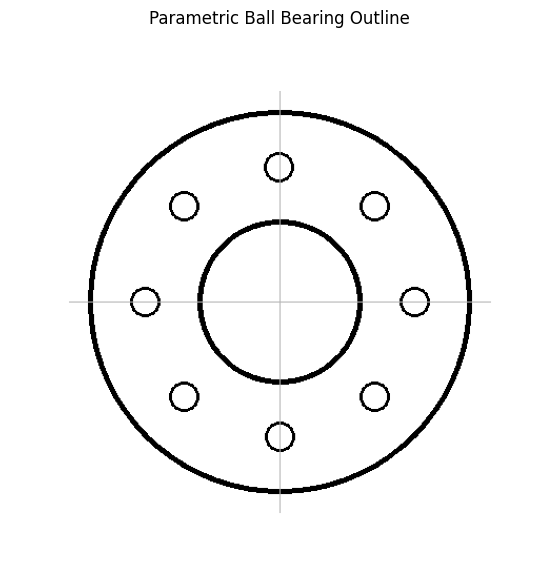

In [35]:

outline = render_industrial_outline(parsed_data)

plt.figure(figsize=(7, 7))
plt.imshow(outline)
plt.title("Parametric Ball Bearing Outline")
plt.axis("off")
plt.show()


In [36]:

outline_path = "industrial_outputs/ball_bearing_outline.png"

outline.save(outline_path)

print("Outline saved:", outline_path)


Outline saved: industrial_outputs/ball_bearing_outline.png


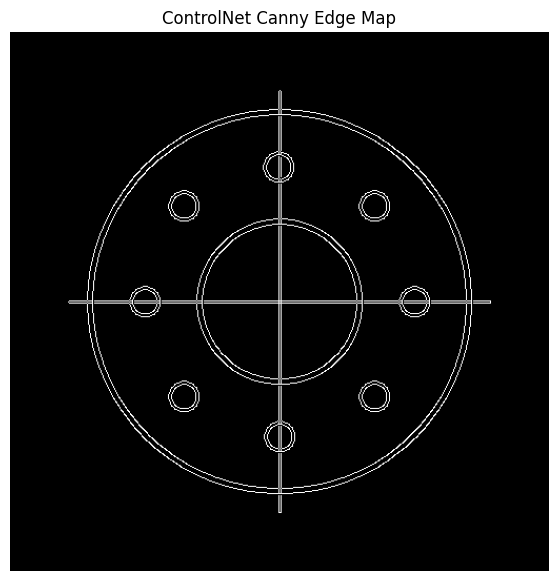

ControlNet edge map created!


In [37]:

outline_cv = cv2.imread(outline_path)

gray = cv2.cvtColor(
    outline_cv,
    cv2.COLOR_BGR2GRAY
)

edge_map = cv2.Canny(
    gray,
    threshold1=50,
    threshold2=150
)

plt.figure(figsize=(7, 7))
plt.imshow(edge_map, cmap="gray")
plt.title("ControlNet Canny Edge Map")
plt.axis("off")
plt.show()

cv2.imwrite(
    "industrial_outputs/ball_bearing_edges.png",
    edge_map
)

print("ControlNet edge map created!")

In [38]:

import gc
import torch

# Release the LLM from GPU memory
if "model" in globals():
    del model

if "tokenizer" in globals():
    del tokenizer

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("GPU memory released!")
    print(torch.cuda.get_device_name(0))

GPU memory released!
Tesla T4


In [39]:

!pip install -q -U diffusers transformers accelerate safetensors

In [40]:

import torch
import gc

from PIL import Image
from diffusers import (
    ControlNetModel,
    StableDiffusionControlNetPipeline,
    UniPCMultistepScheduler
)

print("Image generation libraries imported!")

Image generation libraries imported!


In [41]:

controlnet_id = "lllyasviel/control_v11p_sd15_canny"

controlnet = ControlNetModel.from_pretrained(
    controlnet_id,
    torch_dtype=torch.float16
)

print("ControlNet loaded successfully!")

ControlNet loaded successfully!


In [44]:
from diffusers import StableDiffusionControlNetPipeline

# Instantiate the pipeline using the base model and the loaded controlnet
model_id = "runwayml/stable-diffusion-v1-5"
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    model_id,
    controlnet=controlnet,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

# Check available memory optimization methods
print("Attention slicing available:",
      hasattr(pipe, "enable_attention_slicing"))

print("VAE slicing available:",
      hasattr(pipe, "enable_vae_slicing"))

# Enable VAE slicing only if supported
if hasattr(pipe, "enable_vae_slicing"):
    pipe.enable_vae_slicing()
    print("VAE slicing enabled.")
else:
    print("VAE slicing skipped - not supported in this version.")

# Move pipeline to GPU
pipe = pipe.to("cuda")

print("Stable Diffusion + ControlNet ready!")
print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Attention slicing available: True
VAE slicing available: False
VAE slicing skipped - not supported in this version.
Stable Diffusion + ControlNet ready!
GPU: Tesla T4


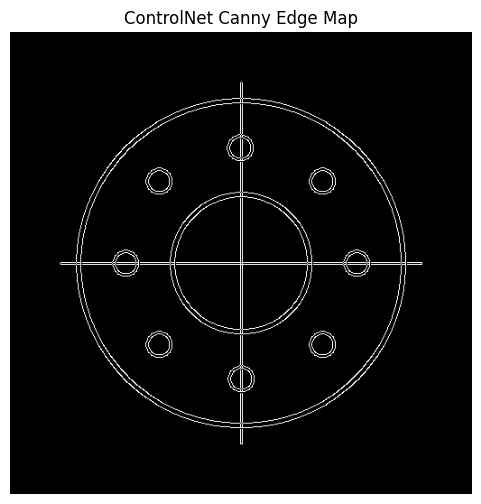

Edge image loaded successfully!


In [45]:

from PIL import Image
import os
import matplotlib.pyplot as plt

# Load the edge map created in Task 5
edge_path = "industrial_outputs/ball_bearing_edges.png"

# Check whether the file exists
if not os.path.exists(edge_path):
    raise FileNotFoundError(
        "Edge map not found. Please rerun Cell 24 from Task 5."
    )

# Load and prepare image
edge_image = Image.open(edge_path).convert("RGB")
edge_image = edge_image.resize((512, 512))

# Display edge map
plt.figure(figsize=(6, 6))
plt.imshow(edge_image)
plt.title("ControlNet Canny Edge Map")
plt.axis("off")
plt.show()

print("Edge image loaded successfully!")


In [46]:

generator = torch.Generator(
    device="cuda"
).manual_seed(42)

result = pipe(
    prompt=positive_prompt,
    negative_prompt=negative_prompt,
    image=edge_image,
    num_inference_steps=25,
    guidance_scale=7.5,
    controlnet_conditioning_scale=1.0,
    generator=generator,
    width=512,
    height=512
)

generated_image = result.images[0]

print("Image generated successfully!")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (113 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['concentric structure , clean industrial geometry , realistic metallic surface , front three - quarter view , centered composition , isolated on a plain white background , professional studio lighting , sharp focus , high detail .']


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/debugpy/_vendored/pydevd/_pydevd_bundle/pydevd_safe_repr.py:128: FutureWarning: Accessing config attribute `__iter__` directly via 'ControlNetModel' object attribute is deprecated. Please access '__iter__' over 'ControlNetModel's config object instead, e.g. 'unet.config.__iter__'.
  if not hasattr(obj, "__iter__"):
/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'StableDiffusionControlNetPipeline' object attribute is deprecated. Please access '__iter__' over 'StableDiffusionControlNetPipeline's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)


Image generated successfully!


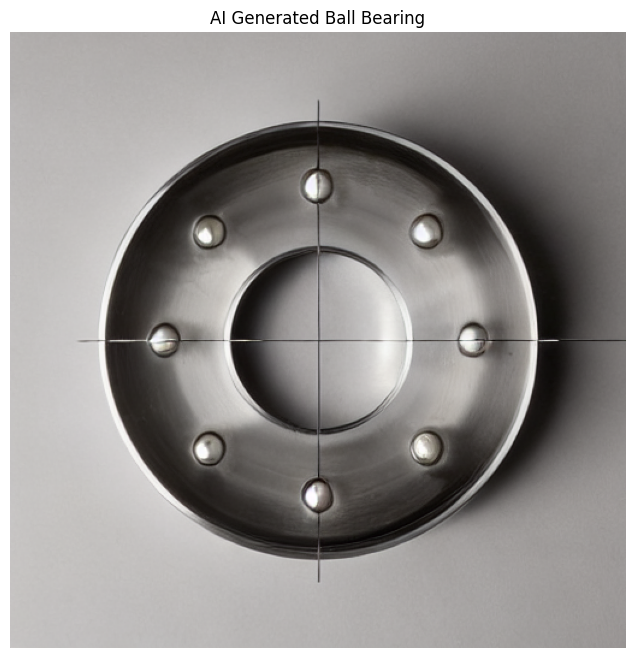

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.imshow(generated_image)
plt.title("AI Generated Ball Bearing")
plt.axis("off")
plt.show()

In [52]:

!pip install -q transformers scikit-image

In [53]:

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from transformers import CLIPProcessor, CLIPModel
from skimage.metrics import structural_similarity as ssim

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [54]:

clip_model_name = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(
    clip_model_name
)

clip_model = CLIPModel.from_pretrained(
    clip_model_name
)

clip_model = clip_model.to("cuda")
clip_model.eval()

print("CLIP model loaded successfully!")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP model loaded successfully!


In [56]:
def calculate_clip_score(image, text):

    inputs = clip_processor(
        text=[text],
        images=image,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=77
    )

    inputs = {
        key: value.to("cuda")
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = clip_model(**inputs)

    image_features = outputs.image_embeds
    text_features = outputs.text_embeds

    image_features = image_features / image_features.norm(
        dim=-1, keepdim=True
    )

    text_features = text_features / text_features.norm(
        dim=-1, keepdim=True
    )

    similarity = (
        image_features @ text_features.T
    ).item()

    return similarity

clip_score = calculate_clip_score(
    generated_image,
    positive_prompt
)

print("CLIP similarity:", round(clip_score, 4))

CLIP similarity: 0.2926


In [57]:

def check_product_features(image, features):

    results = []

    for feature in features:

        description = (
            f"A technical product photograph clearly showing "
            f"a ball bearing with {feature}."
        )

        score = calculate_clip_score(
            image,
            description
        )

        results.append({
            "feature": feature,
            "similarity": round(score, 4)
        })

    return pd.DataFrame(results)

feature_results = check_product_features(
    generated_image,
    parsed_data["features"]
)

display(feature_results)

,feature,similarity
0,inner ring,0.2891
1,outer ring,0.2952
2,sealed design,0.2946


In [58]:

def evaluate_generated_image(image, spec, positive_prompt):

    clip_score = calculate_clip_score(
        image,
        positive_prompt
    )

    features = spec.get("features", [])

    feature_df = check_product_features(
        image,
        features
    )

    if len(feature_df) > 0:
        feature_score = feature_df["similarity"].mean()
    else:
        feature_score = 0

    overall_score = (
        0.5 * clip_score +
        0.5 * feature_score
    )

    return {
        "clip_score": round(clip_score, 4),
        "feature_score": round(feature_score, 4),
        "overall_score": round(overall_score, 4),
        "feature_results": feature_df
    }

evaluation = evaluate_generated_image(
    generated_image,
    parsed_data,
    positive_prompt
)

print("Evaluation Results")
print("-------------------")
print("CLIP Score:", evaluation["clip_score"])
print("Feature Score:", evaluation["feature_score"])
print("Overall Score:", evaluation["overall_score"])

display(evaluation["feature_results"])

Evaluation Results
-------------------
CLIP Score: 0.2926
Feature Score: 0.293
Overall Score: 0.2928


,feature,similarity
0,inner ring,0.2891
1,outer ring,0.2952
2,sealed design,0.2946


In [59]:

human_rating = int(input(
    "Rate the generated image from 1 to 5: "
))

while human_rating < 1 or human_rating > 5:
    human_rating = int(input(
        "Enter a rating between 1 and 5: "
    ))

print("Human rating:", human_rating, "/ 5")

Rate the generated image from 1 to 5: 4
Human rating: 4 / 5


In [60]:

evaluation_record = {
    "product": parsed_data["product"],
    "clip_score": evaluation["clip_score"],
    "feature_score": evaluation["feature_score"],
    "overall_score": evaluation["overall_score"],
    "human_rating": human_rating
}

evaluation_df = pd.DataFrame([evaluation_record])

evaluation_df.to_csv(
    "industrial_outputs/evaluation_results.csv",
    index=False
)

display(evaluation_df)

print("Evaluation results saved!")

,product,clip_score,feature_score,overall_score,human_rating
0,Chrome Steel Ball Bearing,0.2926,0.293,0.2928,4


Evaluation results saved!


In [61]:

def refine_prompt(
    positive_prompt,
    feature_results,
    threshold=0.20
):

    missing_features = feature_results[
        feature_results["similarity"] < threshold
    ]["feature"].tolist()

    if not missing_features:
        return positive_prompt, []

    refinement_text = ", ".join(missing_features)

    improved_prompt = (
        positive_prompt
        + "\nImportant: Clearly show the following "
        + "engineering features: "
        + refinement_text
        + ". Preserve the correct industrial structure "
        + "and proportions."
    )

    return improved_prompt, missing_features

refined_prompt, missing_features = refine_prompt(
    positive_prompt,
    evaluation["feature_results"]
)

print("Features needing attention:", missing_features)
print("\nRefined prompt:")
print(refined_prompt)

Features needing attention: []

Refined prompt:
Professional industrial product catalog photograph of a
    single Chrome Steel Ball Bearing, manufactured from chrome steel.

    Required features: inner ring, outer ring, sealed design.

    Engineering dimensions: 20 mm bore, 47 mm outer diameter, 14 mm width.

    Visual proportions: bore to outer ratio: 0.426, width to outer ratio: 0.298.

    Accurate concentric structure, clean industrial geometry,
    realistic metallic surface, front three-quarter view,
    centered composition, isolated on a plain white background,
    professional studio lighting, sharp focus, high detail.


In [62]:

def automatic_refinement_loop(
    spec,
    initial_prompt,
    negative_prompt,
    edge_image,
    max_rounds=3,
    threshold=0.20
):

    current_prompt = initial_prompt
    history = []

    best_image = None
    best_score = -1
    best_prompt = current_prompt

    for round_number in range(max_rounds + 1):

        print(f"\n========== ROUND {round_number} ==========")

        generator = torch.Generator(
            device="cuda"
        ).manual_seed(42 + round_number)

        result = pipe(
            prompt=current_prompt,
            negative_prompt=negative_prompt,
            image=edge_image,
            num_inference_steps=25,
            guidance_scale=7.5,
            controlnet_conditioning_scale=1.0,
            generator=generator,
            width=512,
            height=512
        )

        candidate_image = result.images[0]

        current_evaluation = evaluate_generated_image(
            candidate_image,
            spec,
            current_prompt
        )

        score = current_evaluation["overall_score"]

        print("CLIP:", current_evaluation["clip_score"])
        print("Feature score:", current_evaluation["feature_score"])
        print("Overall:", score)

        history.append({
            "round": round_number,
            "clip_score": current_evaluation["clip_score"],
            "feature_score": current_evaluation["feature_score"],
            "overall_score": score
        })

        if score > best_score:
            best_score = score
            best_image = candidate_image
            best_prompt = current_prompt

        if round_number == max_rounds:
            print("Maximum refinement rounds reached.")
            break

        new_prompt, missing = refine_prompt(
            current_prompt,
            current_evaluation["feature_results"],
            threshold
        )

        if not missing:
            print("All feature checks passed the threshold.")
            break

        print("Refining:", missing)

        current_prompt = new_prompt

    return best_image, best_prompt, pd.DataFrame(history)

print("Refinement function created!")

Refinement function created!


In [63]:

best_image, best_prompt, refinement_history = (
    automatic_refinement_loop(
        spec=parsed_data,
        initial_prompt=positive_prompt,
        negative_prompt=negative_prompt,
        edge_image=edge_image,
        max_rounds=3,
        threshold=0.20
    )
)

best_image.save(
    "industrial_outputs/best_generated_image.png"
)

print("Best generated image saved!")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (113 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['concentric structure , clean industrial geometry , realistic metallic surface , front three - quarter view , centered composition , isolated on a plain white background , professional studio lighting , sharp focus , high detail .']



========== ROUND 0 ==========


  0%|          | 0/25 [00:00<?, ?it/s]

CLIP: 0.2814
Feature score: 0.2925
Overall: 0.287
All feature checks passed the threshold.
Best generated image saved!


,round,clip_score,feature_score,overall_score
0,0,0.2814,0.2925,0.287


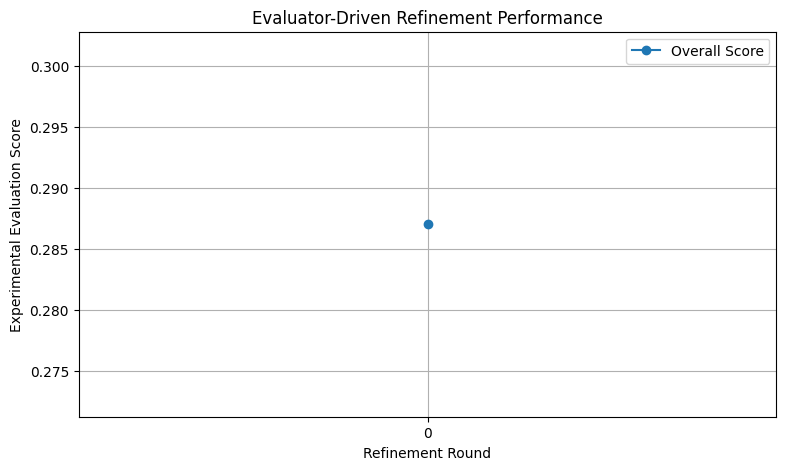

In [64]:

display(refinement_history)

plt.figure(figsize=(9, 5))

plt.plot(
    refinement_history["round"],
    refinement_history["overall_score"],
    marker="o",
    label="Overall Score"
)

plt.xlabel("Refinement Round")
plt.ylabel("Experimental Evaluation Score")
plt.title("Evaluator-Driven Refinement Performance")
plt.xticks(refinement_history["round"])
plt.legend()
plt.grid(True)

plt.savefig(
    "industrial_outputs/refinement_performance.png"
)

plt.show()